# Distância de edição: PD recursiva com memoização x PD iterativa

Projeto e Análise de Algoritmos - Tema 7.9: busca de string mais similar via distância de edição

Elene Firmeza Ohata - Mestrado em Ciência da Computação (IFCE)

## O problema

O tema parte de um cenário de e-commerce: o usuário busca um produto e digita o nome com erro, por exemplo "sansung" em vez de "samsung". Para medir a semelhança entre duas palavras, utiliza-se a distância de edição, definida como o menor número de inserções, remoções e substituições de caracteres necessárias para transformar uma string na outra.

As duas versões implementadas usam a mesma recorrência. Sendo d(i, j) a distância entre os i primeiros caracteres de s e os j primeiros caracteres de t:

```
d(i, 0) = i
d(0, j) = j
d(i, j) = d(i-1, j-1)                                   se s[i] = t[j]
d(i, j) = 1 + min(d(i-1, j-1), d(i-1, j), d(i, j-1))    caso contrário
```

Os três termos do mínimo correspondem a substituir (diagonal), remover (célula de cima) e inserir (célula da esquerda).

A versão recursiva parte de d(m, n) e resolve os subproblemas sob demanda, armazenando cada resultado em uma tabela (memo) para evitar recálculos. A versão iterativa preenche a tabela inteira, linha por linha, a partir de d(0, 0). Em ambos os casos, o tempo e a memória são O(m·n).

Além do valor da distância, as duas funções retornam a sequência de operações (a solução ótima). Ela é obtida percorrendo a tabela de volta a partir de d(m, n) e identificando de qual vizinha veio cada valor.

In [1]:
import sys
import gc
import random
import string
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# a recursão pode chegar a m + n níveis; o limite padrão do Python é 1000
sys.setrecursionlimit(100000)

## Implementação

In [2]:
# Versão 1: recursiva com memoização (top-down)
def edicao_recursiva(s, t):
    m, n = len(s), len(t)
    memo = [[-1] * (n + 1) for _ in range(m + 1)]  # -1: célula ainda não calculada

    def d(i, j):
        if memo[i][j] != -1:
            return memo[i][j]
        if i == 0:
            r = j
        elif j == 0:
            r = i
        elif s[i - 1] == t[j - 1]:  # caracteres iguais: custo zero
            r = d(i - 1, j - 1)
        else:
            r = 1 + min(d(i - 1, j - 1), d(i - 1, j), d(i, j - 1))
        memo[i][j] = r
        return r

    dist = d(m, n)
    return dist, reconstruir(s, t, memo)


# Versão 2: iterativa (bottom-up), preenche a tabela inteira
def edicao_iterativa(s, t):
    m, n = len(s), len(t)
    d = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1):
        d[i][0] = i
    for j in range(n + 1):
        d[0][j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if s[i - 1] == t[j - 1]:
                d[i][j] = d[i - 1][j - 1]
            else:
                d[i][j] = 1 + min(d[i - 1][j - 1], d[i - 1][j], d[i][j - 1])
    return d[m][n], reconstruir(s, t, d)


# Reconstrói as operações percorrendo a tabela de (m, n) até (0, 0).
# Usada pelas duas versões (na recursiva, as vizinhas necessárias já estão no memo).
def reconstruir(s, t, d):
    i, j = len(s), len(t)
    ops = []
    while i > 0 or j > 0:
        if i == 0:
            ops.append(("inserir", t[j - 1]))
            j -= 1
        elif j == 0:
            ops.append(("remover", s[i - 1]))
            i -= 1
        elif s[i - 1] == t[j - 1]:
            ops.append(("manter", s[i - 1]))
            i -= 1
            j -= 1
        elif d[i][j] == d[i - 1][j - 1] + 1:
            ops.append(("substituir", s[i - 1], t[j - 1]))
            i -= 1
            j -= 1
        elif d[i][j] == d[i - 1][j] + 1:
            ops.append(("remover", s[i - 1]))
            i -= 1
        else:
            ops.append(("inserir", t[j - 1]))
            j -= 1
    ops.reverse()  # as operações foram montadas do fim para o início
    return ops

Na reconstrução, quando os caracteres são iguais a operação é sempre "manter". Quando são diferentes, as três vizinhas já foram calculadas (inclusive na versão recursiva, pois a chamada de d(i, j) chama as três), e é possível identificar qual delas originou o valor.

Para verificar a sequência de operações, a função `aplicar` executa as operações sobre s e confere se o resultado é t. Além disso, o número de operações diferentes de "manter" deve ser igual à distância.

In [3]:
def aplicar(s, ops):
    res = []
    k = 0  # posição atual em s
    for op in ops:
        if op[0] == "manter":
            res.append(s[k])
            k += 1
        elif op[0] == "substituir":
            res.append(op[2])
            k += 1
        elif op[0] == "remover":
            k += 1
        else:  # inserir
            res.append(op[1])
    return "".join(res)


def custo(ops):
    return sum(1 for op in ops if op[0] != "manter")


def solucao_valida(s, t, dist, ops):
    return aplicar(s, ops) == t and custo(ops) == dist

## Testes

Inicialmente, alguns casos cujo resultado pode ser verificado manualmente:

In [4]:
casos = [
    ("sansung", "samsung", 1),
    ("iphon", "iphone", 1),
    ("kitten", "sitting", 3),
    ("notebuk", "notebook", 2),
    ("", "abc", 3),
    ("abc", "", 3),
    ("abc", "abc", 0),
]

for s, t, esperado in casos:
    d1, ops1 = edicao_recursiva(s, t)
    d2, ops2 = edicao_iterativa(s, t)
    correto = d1 == d2 == esperado and solucao_valida(s, t, d1, ops1) and solucao_valida(s, t, d2, ops2)
    print(repr(s), "->", repr(t), "| recursiva:", d1, "| iterativa:", d2, "| esperado:", esperado,
          "| ok" if correto else "| ERRO")

'sansung' -> 'samsung' | recursiva: 1 | iterativa: 1 | esperado: 1 | ok
'iphon' -> 'iphone' | recursiva: 1 | iterativa: 1 | esperado: 1 | ok
'kitten' -> 'sitting' | recursiva: 3 | iterativa: 3 | esperado: 3 | ok
'notebuk' -> 'notebook' | recursiva: 2 | iterativa: 2 | esperado: 2 | ok
'' -> 'abc' | recursiva: 3 | iterativa: 3 | esperado: 3 | ok
'abc' -> '' | recursiva: 3 | iterativa: 3 | esperado: 3 | ok
'abc' -> 'abc' | recursiva: 0 | iterativa: 0 | esperado: 0 | ok


In [5]:
# exemplo clássico, para visualizar a sequência de operações
d, ops = edicao_iterativa("kitten", "sitting")
print("distância:", d)
for op in ops:
    print(op)

distância: 3
('substituir', 'k', 's')
('manter', 'i')
('manter', 't')
('manter', 't')
('substituir', 'e', 'i')
('manter', 'n')
('inserir', 'g')


Em seguida, vários pares pequenos gerados aleatoriamente são comparados com a recursão sem memoização (força bruta), que testa todas as possibilidades. Por ser exponencial, ela só é viável para strings curtas (até 7 caracteres neste teste).

In [6]:
# força bruta: recursão sem memoização, exponencial (apenas para strings curtas)
def edicao_forca_bruta(s, t):
    if not s:
        return len(t)
    if not t:
        return len(s)
    return min(
        edicao_forca_bruta(s[:-1], t[:-1]) + (s[-1] != t[-1]),
        edicao_forca_bruta(s[:-1], t) + 1,
        edicao_forca_bruta(s, t[:-1]) + 1,
    )


random.seed(0)
erros = 0
for _ in range(500):
    alfabeto = random.choice(["ab", "abc", string.ascii_lowercase])  # alfabetos pequenos geram mais empates
    s = "".join(random.choices(alfabeto, k=random.randint(0, 7)))
    t = "".join(random.choices(alfabeto, k=random.randint(0, 7)))
    esperado = edicao_forca_bruta(s, t)
    d1, ops1 = edicao_recursiva(s, t)
    d2, ops2 = edicao_iterativa(s, t)
    if not (d1 == d2 == esperado and solucao_valida(s, t, d1, ops1) and solucao_valida(s, t, d2, ops2)):
        erros += 1
print("erros em 500 testes:", erros)

erros em 500 testes: 0


## Experimento 1: strings de mesmo tamanho

As entradas são pares de strings aleatórias (letras de a a z), ambas com tamanho n, para n = 10, 20, ..., 1000. São 100 tamanhos, com 10 pares diferentes para cada um, e as duas versões são executadas exatamente sobre os mesmos pares.

O enunciado recomenda tamanhos a partir de 100 e bem maiores, mas como os dois algoritmos são quadráticos e foram implementados em Python puro, valores acima de 1000 tornariam o experimento excessivamente demorado.

O tempo medido inclui o cálculo da distância e a reconstrução das operações. O coletor de lixo é desativado durante cada medição, para que não interfira nos tempos. Para cada par, verifica-se se as duas versões retornam a mesma distância e se as operações retornadas são válidas.


In [7]:
def string_aleatoria(n):
    return "".join(random.choices(string.ascii_lowercase, k=n))


def medir(f, s, t):
    gc.disable()  # evita que o coletor de lixo interfira na medição
    inicio = time.perf_counter()
    dist, ops = f(s, t)
    fim = time.perf_counter()
    gc.enable()
    return dist, ops, fim - inicio


# executa as duas versões em todos os pares e armazena os resultados em um DataFrame
def rodar(pares_por_tamanho):
    linhas = []
    for (m, n), pares in pares_por_tamanho.items():
        for k, (s, t) in enumerate(pares):
            d1, ops1, t1 = medir(edicao_recursiva, s, t)
            d2, ops2, t2 = medir(edicao_iterativa, s, t)
            linhas.append({
                "m": m, "n": n, "par": k,
                "dist_rec": d1, "dist_it": d2,
                "tempo_rec": t1, "tempo_it": t2,
                "iguais": d1 == d2,
                "validas": solucao_valida(s, t, d1, ops1) and solucao_valida(s, t, d2, ops2),
            })
    return pd.DataFrame(linhas)

In [8]:
random.seed(42)  # semente fixa, para reprodutibilidade
REPETICOES = 10
tamanhos = list(range(10, 1001, 10))

# as entradas são geradas antes, para que as duas versões usem os mesmos pares
entradas1 = {}
for n in tamanhos:
    entradas1[(n, n)] = [(string_aleatoria(n), string_aleatoria(n)) for _ in range(REPETICOES)]

inicio = time.time()
df1 = rodar(entradas1)
print(f"terminou em {time.time() - inicio:.0f} s")
print("pares testados:", len(df1))
print("pares com distâncias diferentes:", (~df1["iguais"]).sum())
print("pares com solução inválida:", (~df1["validas"]).sum())
df1.to_csv("resultados_exp1.csv", index=False)

terminou em 330 s
pares testados: 1000
pares com distâncias diferentes: 0
pares com solução inválida: 0


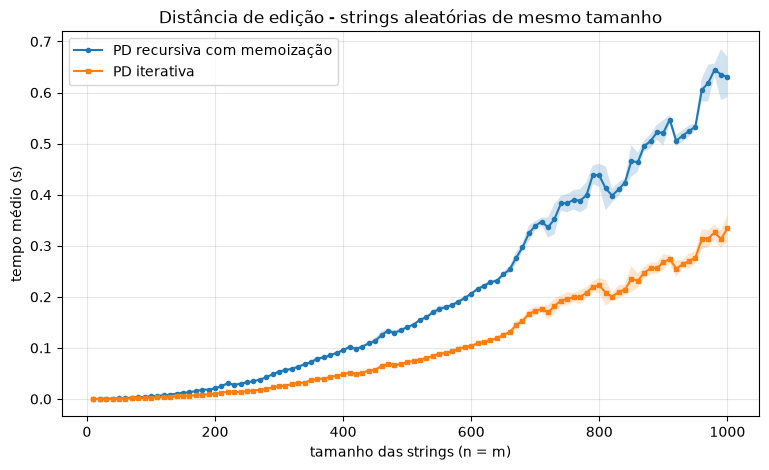

In [9]:
media1 = df1.groupby("n")[["tempo_rec", "tempo_it", "dist_rec"]].mean()
desvio1 = df1.groupby("n")[["tempo_rec", "tempo_it"]].std()

plt.figure(figsize=(9, 5))
plt.plot(media1.index, media1["tempo_rec"], "o-", markersize=3, label="PD recursiva com memoização")
plt.plot(media1.index, media1["tempo_it"], "s-", markersize=3, label="PD iterativa")
plt.fill_between(media1.index, media1["tempo_rec"] - desvio1["tempo_rec"], media1["tempo_rec"] + desvio1["tempo_rec"], alpha=0.2)
plt.fill_between(media1.index, media1["tempo_it"] - desvio1["tempo_it"], media1["tempo_it"] + desvio1["tempo_it"], alpha=0.2)
plt.xlabel("tamanho das strings (n = m)")
plt.ylabel("tempo médio (s)")
plt.title("Distância de edição - strings aleatórias de mesmo tamanho")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("grafico_exp1.png", dpi=150, bbox_inches="tight")
plt.show()

A faixa sombreada corresponde à média mais ou menos um desvio padrão das 10 execuções.

Para verificar se o crescimento é de fato quadrático, o mesmo experimento foi plotado em escala log-log, com ajuste de uma reta para n >= 100. Se o tempo for proporcional a n², a inclinação deve ser próxima de 2.

inclinação recursiva: 2.11
inclinação iterativa: 2.15


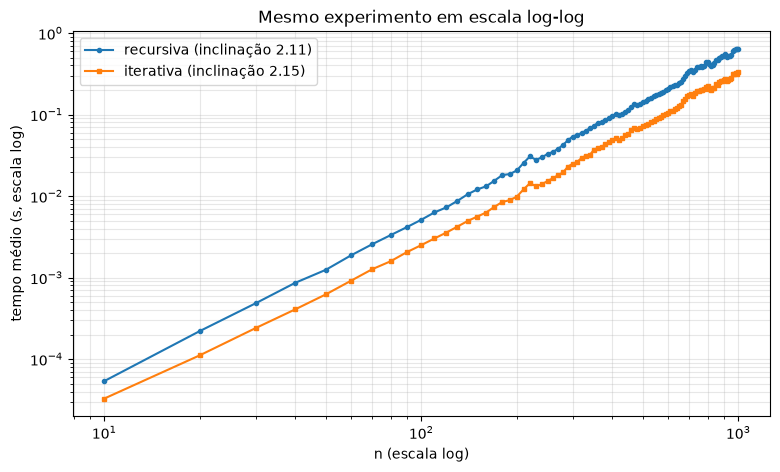

In [10]:
# ajuste de reta em escala log-log, apenas com n >= 100 (para n pequeno o tempo é dominado por overhead)
grandes = media1[media1.index >= 100]
inc_rec = np.polyfit(np.log(grandes.index), np.log(grandes["tempo_rec"]), 1)[0]
inc_it = np.polyfit(np.log(grandes.index), np.log(grandes["tempo_it"]), 1)[0]
print(f"inclinação recursiva: {inc_rec:.2f}")
print(f"inclinação iterativa: {inc_it:.2f}")

plt.figure(figsize=(9, 5))
plt.loglog(media1.index, media1["tempo_rec"], "o-", markersize=3, label=f"recursiva (inclinação {inc_rec:.2f})")
plt.loglog(media1.index, media1["tempo_it"], "s-", markersize=3, label=f"iterativa (inclinação {inc_it:.2f})")
plt.xlabel("n (escala log)")
plt.ylabel("tempo médio (s, escala log)")
plt.title("Mesmo experimento em escala log-log")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.savefig("grafico_exp1_loglog.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
razao1 = media1["tempo_rec"] / media1["tempo_it"]
tabela = media1.loc[[100, 250, 500, 750, 1000], ["tempo_rec", "tempo_it"]].copy()
tabela["recursiva / iterativa"] = razao1.loc[[100, 250, 500, 750, 1000]]
tabela["distância média"] = media1.loc[[100, 250, 500, 750, 1000], "dist_rec"]
print(f"razão média (n >= 100): {razao1[razao1.index >= 100].mean():.2f}")
tabela.round(4)

razão média (n >= 100): 2.01


,tempo_rec,tempo_it,recursiva / iterativa,distância média
n,,,,
100,0.0051,0.0025,2.0470,90.8
250,0.0328,0.0153,2.1455,224.3
500,0.1408,0.0720,1.9564,443.7
750,0.3835,0.1962,1.9541,665.7
1000,0.6306,0.3341,1.8876,883.1


## Experimento 2: um tamanho fixo

Como a entrada tem duas dimensões (os tamanhos de s e de t), também foi realizado um experimento com |s| = 500 fixo e |t| variando de 10 a 1000, com 10 pares por tamanho. Nesse caso, espera-se crescimento linear em n, já que m é constante.

terminou em 249 s
pares com distâncias diferentes: 0
pares com solução inválida: 0


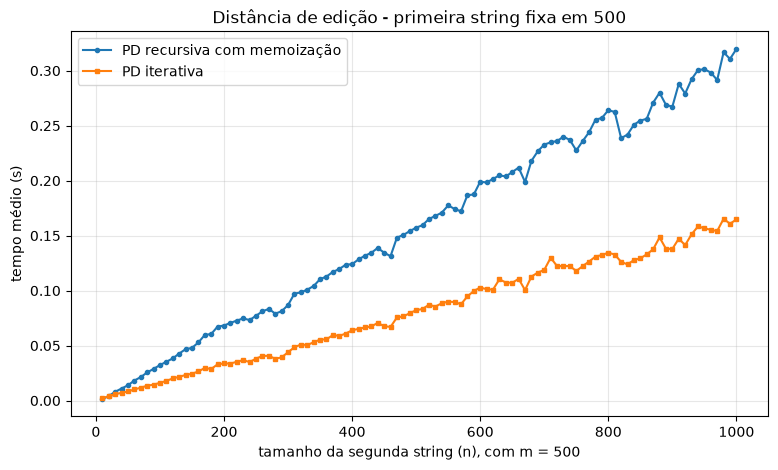

In [12]:
random.seed(7)
M_FIXO = 500  # tamanho fixo de s
entradas2 = {}
for n in tamanhos:
    entradas2[(M_FIXO, n)] = [(string_aleatoria(M_FIXO), string_aleatoria(n)) for _ in range(REPETICOES)]

inicio = time.time()
df2 = rodar(entradas2)
print(f"terminou em {time.time() - inicio:.0f} s")
print("pares com distâncias diferentes:", (~df2["iguais"]).sum())
print("pares com solução inválida:", (~df2["validas"]).sum())
df2.to_csv("resultados_exp2.csv", index=False)

media2 = df2.groupby("n")[["tempo_rec", "tempo_it"]].mean()
plt.figure(figsize=(9, 5))
plt.plot(media2.index, media2["tempo_rec"], "o-", markersize=3, label="PD recursiva com memoização")
plt.plot(media2.index, media2["tempo_it"], "s-", markersize=3, label="PD iterativa")
plt.xlabel("tamanho da segunda string (n), com m = 500")
plt.ylabel("tempo médio (s)")
plt.title("Distância de edição - primeira string fixa em 500")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("grafico_exp2.png", dpi=150, bbox_inches="tight")
plt.show()

## Experimento 3: strings parecidas

No cenário do e-commerce, as duas palavras costumam ser muito parecidas (apenas um erro de digitação). Isso pode favorecer a versão recursiva: quando os caracteres são iguais, ela chama apenas d(i-1, j-1) e, em princípio, deixa de visitar boa parte da tabela. A versão iterativa sempre preenche todas as m·n células.

Para avaliar esse efeito, fixou-se n = 1000, gerou-se uma string aleatória s e criou-se t aplicando sobre s uma quantidade k de erros em posições aleatórias (troca, remoção ou inserção de um caractere), com k variando de 0 a 500 e 10 pares para cada valor. Também foi contado o número de células da tabela calculadas pela versão recursiva.

In [13]:
# aplica k erros aleatórios em s (troca, remoção ou inserção de um caractere)
def com_erros(s, k):
    t = list(s)
    for _ in range(k):
        pos = random.randrange(len(t) + 1)
        tipo = random.choice(["trocar", "remover", "inserir"])
        if tipo == "trocar" and pos < len(t):
            t[pos] = random.choice(string.ascii_lowercase)
        elif tipo == "remover" and pos < len(t):
            del t[pos]
        else:
            t.insert(pos, random.choice(string.ascii_lowercase))
    return "".join(t)


# conta quantas células do memo a versão recursiva calculou
def celulas_visitadas(s, t):
    m, n = len(s), len(t)
    memo = [[-1] * (n + 1) for _ in range(m + 1)]
    edicao_recursiva_com_memo(s, t, memo)
    return sum(1 for linha in memo for x in linha if x != -1)


# mesma recursão da versão 1, recebendo o memo como parâmetro para permitir a contagem
def edicao_recursiva_com_memo(s, t, memo):
    def d(i, j):
        if memo[i][j] != -1:
            return memo[i][j]
        if i == 0:
            r = j
        elif j == 0:
            r = i
        elif s[i - 1] == t[j - 1]:
            r = d(i - 1, j - 1)
        else:
            r = 1 + min(d(i - 1, j - 1), d(i - 1, j), d(i, j - 1))
        memo[i][j] = r
        return r
    return d(len(s), len(t))


random.seed(3)
N3 = 1000
qtd_erros = [0, 1, 2, 3, 5, 10, 20, 50, 100, 200, 500]
linhas = []
for e in qtd_erros:
    for k in range(REPETICOES):
        s = string_aleatoria(N3)
        t = com_erros(s, e)
        d1, ops1, t1 = medir(edicao_recursiva, s, t)
        d2, ops2, t2 = medir(edicao_iterativa, s, t)
        linhas.append({
            "erros": e, "dist_rec": d1, "dist_it": d2,
            "tempo_rec": t1, "tempo_it": t2,
            "frac_celulas": celulas_visitadas(s, t) / ((len(s) + 1) * (len(t) + 1)),
            "iguais": d1 == d2,
            "validas": solucao_valida(s, t, d1, ops1) and solucao_valida(s, t, d2, ops2),
        })
df3 = pd.DataFrame(linhas)
df3.to_csv("resultados_exp3.csv", index=False)
print("pares com distâncias diferentes:", (~df3["iguais"]).sum())
print("pares com solução inválida:", (~df3["validas"]).sum())

media3 = df3.groupby("erros")[["tempo_rec", "tempo_it", "frac_celulas", "dist_rec"]].mean()
media3

pares com distâncias diferentes: 0
pares com solução inválida: 0


,tempo_rec,tempo_it,frac_celulas,dist_rec
erros,,,,
0,0.002506,0.321774,0.000999,0.0
1,0.188757,0.319202,0.290037,1.0
2,0.201204,0.333740,0.298751,2.0
3,0.332913,0.329842,0.502762,3.0
5,0.376957,0.319384,0.580350,4.8
10,0.438545,0.293808,0.725219,9.7
20,0.541044,0.309282,0.833592,19.7
50,0.643164,0.336189,0.908512,48.1
100,0.570268,0.294232,0.936425,93.9


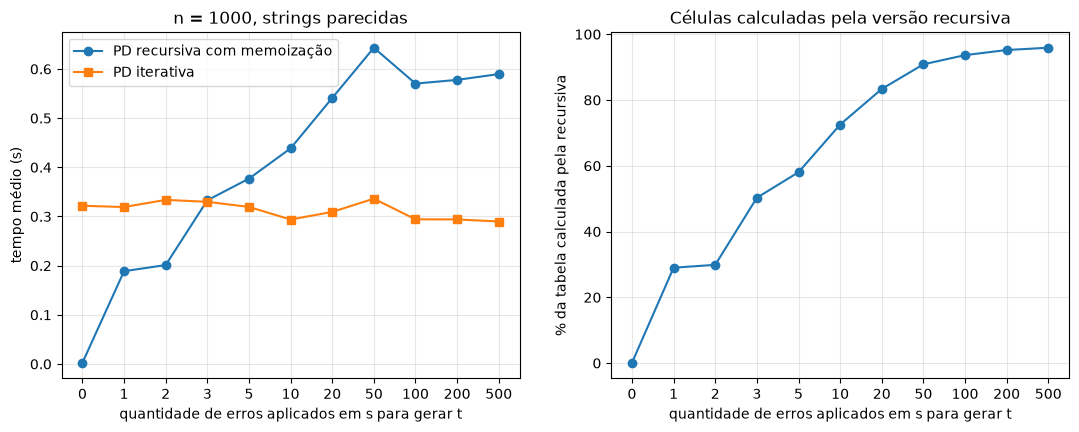

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x = range(len(media3))
rotulos = [str(e) for e in media3.index]
ax[0].plot(x, media3["tempo_rec"], "o-", label="PD recursiva com memoização")
ax[0].plot(x, media3["tempo_it"], "s-", label="PD iterativa")
ax[0].set_xticks(x, rotulos)
ax[0].set_xlabel("quantidade de erros aplicados em s para gerar t")
ax[0].set_ylabel("tempo médio (s)")
ax[0].set_title("n = 1000, strings parecidas")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(x, media3["frac_celulas"] * 100, "o-", color="C0")
ax[1].set_xticks(x, rotulos)
ax[1].set_xlabel("quantidade de erros aplicados em s para gerar t")
ax[1].set_ylabel("% da tabela calculada pela recursiva")
ax[1].set_title("Células calculadas pela versão recursiva")
ax[1].grid(alpha=0.3)
plt.savefig("grafico_exp3.png", dpi=150, bbox_inches="tight")
plt.show()

## Discussão

As duas versões retornaram a mesma distância em todos os 2110 pares testados nos experimentos (1000 no primeiro, 1000 no segundo e 110 no terceiro), e as operações retornadas sempre transformaram s em t com o número correto de passos. Somado aos 500 testes contra a força bruta, esse resultado dá boa confiança na correção das implementações.

No experimento 1, as duas curvas têm formato de parábola, como esperado para O(n²). Em escala log-log, as inclinações foram 2,14 (recursiva) e 2,21 (iterativa), próximas de 2. O valor ligeiramente acima de 2 provavelmente se deve ao custo de alocar tabelas cada vez maiores e ao ruído da máquina.

A versão recursiva foi mais lenta em todos os tamanhos, levando em média 2,2 vezes o tempo da iterativa (com n = 1000, 0,44 s contra 0,23 s). Com strings aleatórias, as duas calculam praticamente as mesmas células; portanto, a diferença não está na complexidade, e sim no custo de cada célula. Na recursiva, cada célula corresponde a uma chamada de função, com consulta ao memo e uso da pilha, e chamadas de função têm custo elevado em Python. A iterativa realiza a mesma conta dentro de dois laços. Outro ponto desfavorável à recursiva é a profundidade da recursão, que chega a m + n e exigiu aumentar o limite de recursão do Python.

No experimento 2, com m = 500 fixo, o tempo cresce linearmente com n, o que é coerente com O(m·n). A recursiva continuou cerca de 2 vezes mais lenta. Os pontos oscilam mais porque cada medição é curta e fica mais sensível a interferências do sistema.

O experimento 3 trouxe o resultado mais interessante. Com strings iguais, a recursiva percorre apenas a diagonal (0,1% da tabela) e leva 0,002 s, contra 0,2 s da iterativa. Porém, com apenas 1 erro, ela já calcula em média 29% da tabela, e a partir de 3 erros passa a calcular mais da metade e fica mais lenta que a iterativa.

Isso ocorre porque, após o erro, a recursão passa a comparar caracteres deslocados, que quase sempre são diferentes; com isso, ela chama as três vizinhas e se espalha por toda a região da tabela anterior ao erro. Com um único erro, a quantidade de células calculadas depende da posição: próximo ao fim da palavra, praticamente a tabela inteira; próximo ao início, quase nada. Para uma posição aleatória, a média é próxima de 1/3, o que está de acordo com o valor observado. A vantagem da recursiva, portanto, só aparece quando as strings são iguais ou diferem em 1 ou 2 posições.

Para o sistema de busca do e-commerce, a versão iterativa é a mais adequada: é mais rápida no caso geral, não depende do limite de recursão e tem tempo previsível, sempre proporcional a m·n. A recursiva só compensaria se a maior parte das buscas fosse digitada quase corretamente.

Como limitação, n foi limitado a 1000, pois em Python puro os dois algoritmos ficam lentos para tamanhos maiores (a execução completa do notebook leva cerca de 9 minutos). Para nomes de produtos, essa faixa é mais que suficiente, já que as palavras têm poucas dezenas de caracteres.